# RabTech Academy Task 4 — Supervised Modeling & Tuning

Train and compare four models, tune hyperparameters with stratified 5-fold cross-validation, evaluate metrics, plot ROC curves/confusion matrix, and save the champion model.

Dataset: Breast Cancer Wisconsin Diagnostic dataset bundled with scikit-learn. Target: 0=malignant, 1=benign. Educational use only; not for clinical decisions.

## 1. Imports and load data

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier

data = load_breast_cancer(as_frame=True)
X, y = data.data.copy(), data.target.copy()
X["radius_band"] = pd.cut(X["mean radius"], [-np.inf, 12, 16, np.inf], labels=["small","medium","large"]).astype("object")
print("Dataset shape:", X.shape)
print("Target counts:", y.value_counts().sort_index())


Dataset shape: (569, 31)
Target counts: target
0    212
1    357
Name: count, dtype: int64


## 2. Train/test split and preprocessing
Split before fitting transformations. Preprocessing remains inside each pipeline to avoid leakage.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()
preprocessor = ColumnTransformer([
 ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
 ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
print("Training rows:", len(X_train), "Test rows:", len(X_test))
print("Numeric features:", len(num_cols), "Categorical:", cat_cols)


Training rows: 455 Test rows: 114
Numeric features: 30 Categorical: ['radius_band']


## 3. Tune four architectures
GridSearchCV uses stratified 5-fold cross-validation and optimizes F1 score.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grids = {
 "Logistic Regression": (LogisticRegression(max_iter=3000, random_state=42), {"classifier__C":[0.1,1,10]}),
 "Random Forest": (RandomForestClassifier(random_state=42), {"classifier__n_estimators":[100,200], "classifier__max_depth":[None,8], "classifier__min_samples_leaf":[1,2]}),
 "Extra Trees": (ExtraTreesClassifier(random_state=42), {"classifier__n_estimators":[100,200], "classifier__max_depth":[None,8], "classifier__min_samples_leaf":[1,2]}),
 "Gradient Boosting": (GradientBoostingClassifier(random_state=42), {"classifier__n_estimators":[50,100], "classifier__learning_rate":[0.05,0.1], "classifier__max_depth":[1,2]})
}
searches, cv_rows = {}, []
for name, (estimator, grid) in grids.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({"Model":name, "Best CV F1":search.best_score_, "Best parameters":search.best_params_})
    print(name, "best CV F1:", round(search.best_score_,4))
display(pd.DataFrame(cv_rows))


Logistic Regression best CV F1: 0.9861
Random Forest best CV F1: 0.9701
Extra Trees best CV F1: 0.972
Gradient Boosting best CV F1: 0.9702


,Model,Best CV F1,Best parameters
0,Logistic Regression,0.986116,{'classifier__C': 0.1}
1,Random Forest,0.970122,"{'classifier__max_depth': None, 'classifier__m..."
2,Extra Trees,0.971988,"{'classifier__max_depth': None, 'classifier__m..."
3,Gradient Boosting,0.970219,"{'classifier__learning_rate': 0.1, 'classifier..."


## 4. Compare tuned models on test data

In [4]:
rows=[]
for name, search in searches.items():
    model=search.best_estimator_
    pred=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
    rows.append({"Model":name, "CV F1":search.best_score_, "Accuracy":accuracy_score(y_test,pred),
      "Precision (benign=1)":precision_score(y_test,pred,zero_division=0),
      "Recall (benign=1)":recall_score(y_test,pred,zero_division=0),
      "F1 (benign=1)":f1_score(y_test,pred,zero_division=0), "ROC-AUC":roc_auc_score(y_test,prob)})
comparison_df=pd.DataFrame(rows).sort_values(["CV F1","ROC-AUC"],ascending=False).reset_index(drop=True)
display(comparison_df.round(4))


,Model,CV F1,Accuracy,Precision (benign=1),Recall (benign=1),F1 (benign=1),ROC-AUC
0,Logistic Regression,0.9861,0.9737,0.9726,0.9861,0.9793,0.9957
1,Extra Trees,0.9720,0.9298,0.9444,0.9444,0.9444,0.9888
2,Gradient Boosting,0.9702,0.9474,0.9459,0.9722,0.9589,0.9911
3,Random Forest,0.9701,0.9561,0.9589,0.9722,0.9655,0.9934


## 5. ROC curves

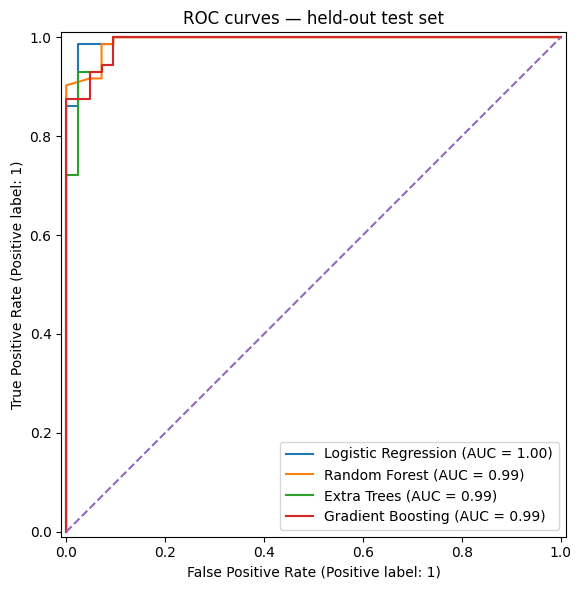

In [5]:
fig, ax = plt.subplots(figsize=(8,6))
for name, search in searches.items():
    RocCurveDisplay.from_estimator(search.best_estimator_, X_test, y_test, name=name, ax=ax)
ax.plot([0,1],[0,1], linestyle="--", label="Chance")
ax.set_title("ROC curves — held-out test set")
plt.tight_layout(); plt.show()


## 6. Champion model and confusion matrix

Champion model selected by CV F1: Logistic Regression
Best parameters: {'classifier__C': 0.1}
               precision    recall  f1-score   support

malignant (0)       0.98      0.95      0.96        42
   benign (1)       0.97      0.99      0.98        72

     accuracy                           0.97       114
    macro avg       0.97      0.97      0.97       114
 weighted avg       0.97      0.97      0.97       114



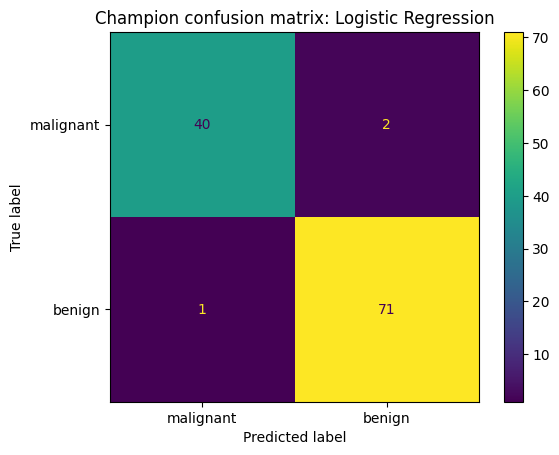

In [6]:
champion_name = comparison_df.loc[0,"Model"]
champion = searches[champion_name].best_estimator_
pred = champion.predict(X_test)
print("Champion model selected by CV F1:", champion_name)
print("Best parameters:", searches[champion_name].best_params_)
print(classification_report(y_test, pred, target_names=["malignant (0)","benign (1)"], zero_division=0))
ConfusionMatrixDisplay.from_estimator(champion, X_test, y_test, display_labels=["malignant","benign"])
plt.title("Champion confusion matrix: " + champion_name)
plt.show()


## 7. Save and reload champion

In [7]:
model_path="champion_model.joblib"
joblib.dump(champion, model_path)
print("Saved model:", model_path)
loaded=joblib.load(model_path)
sample=X_test.iloc[[0]]
prediction=loaded.predict(sample)[0]; probabilities=loaded.predict_proba(sample)[0]
print("Example predicted class:", data.target_names[prediction])
print("Probability malignant:", round(float(probabilities[0]),4))
print("Probability benign:", round(float(probabilities[1]),4))


Saved model: champion_model.joblib
Example predicted class: malignant
Probability malignant: 1.0
Probability benign: 0.0


## 8. Conclusion
Four architectures are tuned using stratified 5-fold GridSearchCV. The notebook produces a comparison table, ROC curves, a champion confusion matrix, and `champion_model.joblib`. High performance on one split does not establish real-world reliability. Educational use only.